# Ensemble precipitation and temperature

Time-mean ensemble precipitation and temperature on the Alaska domain
(1980-01-01 through 2024-12-29) from `prod_complete_ens_timmean.nc`.
Pass `prod_complete_ens_timstd.nc` to add a second row with the ensemble
standard deviation of each field.

`prcp` in both files is a daily amount. The maps multiply it by 365.25 so
the colorbars are in mm yr$^{-1}$. `tmean` is already in °C.

The mean maps use the reference climate-map legend: equal-height
precipitation bins from under 10 to over 5000 mm yr$^{-1}$, and 1°C
temperature steps from −15 to 5°C. The standard-deviation maps use
sequential legends scaled to the ensemble spread. Coastline and the
Canada–United States border are drawn in gray over the valid land cells.


In [16]:
from pathlib import Path

import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from matplotlib.colors import ListedColormap
from shapely.geometry import box

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 8,
    "axes.labelsize": 9,
    "axes.titlesize": 9,
    "axes.linewidth": 0.5,
    "axes.unicode_minus": False,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.04,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

DATA_PATH = Path("/Users/dcasson/Data/snowda/data_for_plotting/prod_complete_ens_timmean.nc")
STD_PATH = Path("/Users/dcasson/Data/snowda/data_for_plotting/prod_complete_ens_timstd.nc")
COAST_PATH = Path("/Users/dcasson/Data/GISData/coastline/ne_10m_coastline.shp")
COUNTRIES_PATH = Path("/Users/dcasson/Data/GISData/World_Countries.gpkg")
FIG_DIR = Path("/Users/dcasson/GitHub/snowda/notebooks/visualization_testing/figs")

# Mean daily precipitation (mm day^-1) to a mean annual total (mm yr^-1).
DAYS_PER_YEAR = 365.25

# Boundaries sit between the swatches. The first color is below the first
# boundary and the last color is above the last boundary.
PRECIP_LEVELS = np.array(
    [10, 50, 100, 150, 200, 250, 300, 400, 500, 750, 1000, 2000, 3000, 4000, 5000],
    dtype=float,
)
PRECIP_COLORS = [
    "#856737",  # < 10
    "#a4874a",  # 10–50
    "#ceaf64",  # 50–100
    "#e1ce77",  # 100–150
    "#d1dc84",  # 150–200
    "#c2eb91",  # 200–250
    "#a0ebaf",  # 250–300
    "#82ebd3",  # 300–400
    "#77d9e8",  # 400–500
    "#5eabe7",  # 500–750
    "#457ce6",  # 750–1000
    "#2c4dd3",  # 1000–2000
    "#201fbe",  # 2000–3000
    "#1e0ba5",  # 3000–4000
    "#171b8b",  # 4000–5000
    "#18316f",  # > 5000
]
PRECIP_LABELS = [f"{int(level)}" for level in PRECIP_LEVELS]
PRECIP_LABELS[-1] = ">5000"

# One color per 1°C step from -15 to 5, plus a color below -15 and above 5.
TEMP_EDGES = np.arange(-15, 6)
TEMP_COLORS = [
    "#315bad",  # < -15
    "#315bad",  # -15 to -14
    "#3b6dbb",  # -14 to -13
    "#4c8cd2",  # -13 to -12
    "#579fe0",  # -12 to -11
    "#62b2eb",  # -11 to -10
    "#65bacc",  # -10 to -9
    "#65bacc",  # -9 to -8
    "#80cacc",  # -8 to -7
    "#a7dabb",  # -7 to -6
    "#c7e493",  # -6 to -5
    "#d1e565",  # -5 to -4
    "#f2f054",  # -4 to -3
    "#f2f054",  # -3 to -2
    "#f6df54",  # -2 to -1
    "#f2c945",  # -1 to 0
    "#eba13c",  # 0 to 1
    "#e57a34",  # 1 to 2
    "#df5530",  # 2 to 3
    "#c93531",  # 3 to 4
    "#c93531",  # 4 to 5
    "#973130",  # > 5
]
TEMP_TICKS = np.array([-15, -10, -5, 0, 5])
TEMP_LABELS = ["<-15", "-10", "-5", "0", ">5"]

# Ensemble spread is much smaller than the mean, so these breaks are separate.
PRECIP_STD_LEVELS = np.array([10, 15, 20, 25, 30, 40, 50, 75, 100, 150], dtype=float)
PRECIP_STD_COLORS = [
    "#f4fbc0",
    "#e1f3b2",
    "#c4e8b4",
    "#92d5b9",
    "#65c3bf",
    "#3db2c4",
    "#2397c1",
    "#2076b3",
    "#2355a4",
    "#253896",
    "#13266f",
]
PRECIP_STD_LABELS = [f"{int(level)}" for level in PRECIP_STD_LEVELS]
PRECIP_STD_LABELS[-1] = ">150"

TEMP_STD_EDGES = np.array([0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.10])
TEMP_STD_COLORS = [
    "#fff4b0",
    "#fee38b",
    "#feca66",
    "#fea848",
    "#fd863a",
    "#fc4f2a",
    "#e6211e",
    "#c70723",
    "#970026",
]
TEMP_STD_LABELS = [f"{level:.2f}" for level in TEMP_STD_EDGES]
TEMP_STD_LABELS[-1] = ">0.10"

if len(PRECIP_COLORS) != len(PRECIP_LEVELS) + 1:
    raise ValueError("Precipitation colors must include one swatch beyond each end.")
if len(TEMP_COLORS) != len(TEMP_EDGES) + 1:
    raise ValueError("Temperature colors must include one swatch beyond each end.")
if len(PRECIP_STD_COLORS) != len(PRECIP_STD_LEVELS) + 1:
    raise ValueError("Precipitation standard-deviation colors must include one swatch beyond each end.")
if len(TEMP_STD_COLORS) != len(TEMP_STD_EDGES) + 1:
    raise ValueError("Temperature standard-deviation colors must include one swatch beyond each end.")


def save_figure(fig, name):
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    png = FIG_DIR / f"{name}.png"
    pdf = FIG_DIR / f"{name}.pdf"
    fig.savefig(png)
    fig.savefig(pdf)
    print(png)
    print(pdf)


In [24]:
def _grid_extent(lon, lat):
    dlon = float(np.median(np.diff(lon)))
    dlat = float(np.median(np.diff(lat)))
    return [
        float(lon[0] - dlon / 2.0),
        float(lon[-1] + dlon / 2.0),
        float(lat[0] - dlat / 2.0),
        float(lat[-1] + dlat / 2.0),
    ]


def _classify(values, edges):
    """Bin index for each cell. Values below the first edge are 0."""
    classes = np.digitize(values, edges).astype(float)
    classes[~np.isfinite(values)] = np.nan
    return classes


def _load_boundaries(extent):
    left, right, bottom, top = extent
    map_box = box(left, bottom, right, top)
    coastline = gpd.clip(
        gpd.read_file(COAST_PATH, bbox=(left, bottom, right, top)),
        map_box,
    )
    countries = gpd.read_file(COUNTRIES_PATH)
    countries = countries.loc[countries["ISO"].isin(["US", "CA"]), ["ISO", "geometry"]].to_crs(4326)
    countries = gpd.clip(countries, map_box)
    united_states = countries.loc[countries["ISO"] == "US"].geometry.union_all()
    canada = countries.loc[countries["ISO"] == "CA"].geometry.union_all()
    border = gpd.GeoSeries(
        [united_states.boundary.intersection(canada.boundary)],
        crs="EPSG:4326",
    )
    return coastline, border


def _draw_map(ax, classes, colors, extent, coastline, border):
    cmap = ListedColormap(colors)
    cmap.set_bad((1, 1, 1, 0))
    n_classes = len(colors)
    image = ax.imshow(
        np.ma.masked_invalid(classes),
        extent=extent,
        origin="lower",
        cmap=cmap,
        vmin=-0.5,
        vmax=n_classes - 0.5,
        interpolation="nearest",
        zorder=1,
    )
    coastline.plot(ax=ax, color="#5a5a5a", linewidth=0.45, zorder=2)
    border.plot(ax=ax, color="#5a5a5a", linewidth=0.45, zorder=3)
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    latitude_center = 0.5 * (extent[2] + extent[3])
    ax.set_aspect(1.0 / np.cos(np.deg2rad(latitude_center)))
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.5)
        spine.set_color("0.15")
    return image


def _add_colorbar(fig, ax, image, ticks, labels, unit):
    colorbar = fig.colorbar(image, ax=ax, fraction=0.045, pad=0.02, ticks=ticks)
    colorbar.ax.set_yticklabels(labels)
    colorbar.ax.set_title(unit, fontsize=8, pad=4)
    colorbar.outline.set_linewidth(0.5)
    colorbar.ax.tick_params(length=2.5, width=0.45, labelsize=6.5)
    return colorbar


def plot_ensemble_climate(dataset, std_dataset=None):
    """Draw ensemble-mean precipitation and temperature.

    ``prcp`` is a daily amount and is converted to mm yr$^{-1}$ with 365.25
    days per year. ``tmean`` is plotted in °C. If ``std_dataset`` is given,
    a second row shows the ensemble standard deviation of each field, with
    the same daily-to-annual conversion for precipitation. Returns the figure.
    """
    precip = dataset["prcp"].squeeze(drop=True).values * DAYS_PER_YEAR
    temperature = dataset["tmean"].squeeze(drop=True).values
    lon = dataset["lon"].values
    lat = dataset["lat"].values
    if lat[0] > lat[-1] or lon[0] > lon[-1]:
        raise ValueError("Expected latitude and longitude to increase with index.")

    extent = _grid_extent(lon, lat)
    coastline, border = _load_boundaries(extent)
    precip_classes = _classify(precip, PRECIP_LEVELS)
    temp_classes = _classify(temperature, TEMP_EDGES)
    # Boundary between class i and i+1 is the level that separates them.
    precip_ticks = np.arange(len(PRECIP_LEVELS)) + 0.5
    temp_ticks = np.searchsorted(TEMP_EDGES, TEMP_TICKS) + 0.5

    rows = [[
        (precip_classes, PRECIP_COLORS, precip_ticks, PRECIP_LABELS, r"       mm yr$^{-1}$", "a", "Mean Annual Precipitation"),
        (temp_classes, TEMP_COLORS, temp_ticks, TEMP_LABELS, "°C", "b", "Mean Daily Temperature"),
    ]]
    if std_dataset is not None:
        std_precip = std_dataset["prcp"].squeeze(drop=True).values * DAYS_PER_YEAR
        std_temperature = std_dataset["tmean"].squeeze(drop=True).values
        if std_precip.shape != precip.shape or std_temperature.shape != temperature.shape:
            raise ValueError("Standard-deviation grid does not match the mean grid.")
        precip_std_ticks = np.arange(len(PRECIP_STD_LEVELS)) + 0.5
        temp_std_ticks = np.arange(len(TEMP_STD_EDGES)) + 0.5
        rows.append([
            (_classify(std_precip, PRECIP_STD_LEVELS), PRECIP_STD_COLORS, precip_std_ticks, PRECIP_STD_LABELS, r"      mm yr$^{-1}$", "c", "Annual Precipitation Standard Deviation"),
            (_classify(std_temperature, TEMP_STD_EDGES), TEMP_STD_COLORS, temp_std_ticks, TEMP_STD_LABELS, "°C", "d", "Daily Temperature Standard Deviation"),
        ])

    fig, axes = plt.subplots(
        len(rows),
        2,
        figsize=(7.8, 3 * len(rows)),
        constrained_layout=True,
        squeeze=False,
    )
    for i, row in enumerate(rows):
        for j, (classes, colors, ticks, labels, unit, letter, title) in enumerate(row):
            image = _draw_map(axes[i, j], classes, colors, extent, coastline, border)
            _add_colorbar(fig, axes[i, j], image, ticks, labels, unit)
            axes[i, j].set_title(f"({letter}) {title}", loc="left", fontsize=10, pad=4)
    return fig


/Users/dcasson/GitHub/snowda/notebooks/visualization_testing/figs/ensemble_precip_temperature.png
/Users/dcasson/GitHub/snowda/notebooks/visualization_testing/figs/ensemble_precip_temperature.pdf


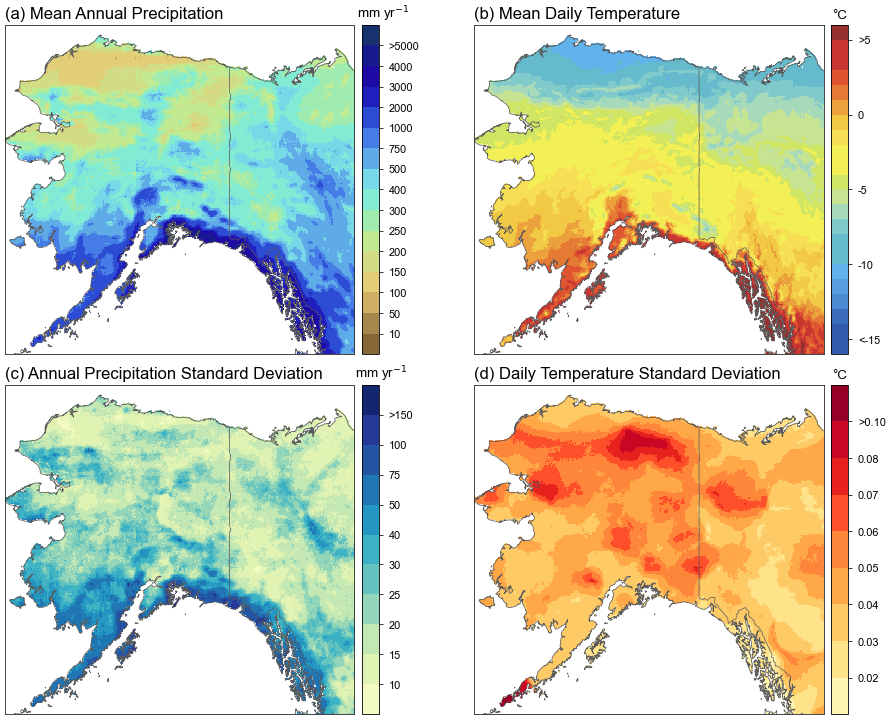

In [25]:
dataset = xr.open_dataset(DATA_PATH)
std_dataset = xr.open_dataset(STD_PATH)
fig = plot_ensemble_climate(dataset, std_dataset)
dataset.close()
std_dataset.close()
save_figure(fig, "ensemble_precip_temperature")
plt.show()
